# The forest that cannot follow growth

**A random forest can pass a backtest and still be unable to forecast a growing business.**

An airline plans next year's seats from its monthly passenger counts. Traffic has grown every year, so the forecast has to grow too. We reach for a random forest fed with the last 12 months, a common first choice, and it beats the usual benchmark at five of six dates. Then TimeGym's scorecard shows what that backtest did not: the forest fails on any series with a trend. The textbook fix, forecasting month-to-month changes, improves the backtest and wrecks the scorecard. A different learner fixes both.

*Data: monthly international airline passengers, 1949 to 1960, from Box, Jenkins and Reinsel ([source and license](data/README.md#airline-passengers)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

from timegym import Pipeline, SeasonalLastValueForecaster, cases_from_series
from timegym.metrics import mase
from timegym.target import DifferenceTransform

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Twelve years of growth

The series counts passengers per month, in thousands. `load` returns it as a table with one row per month.

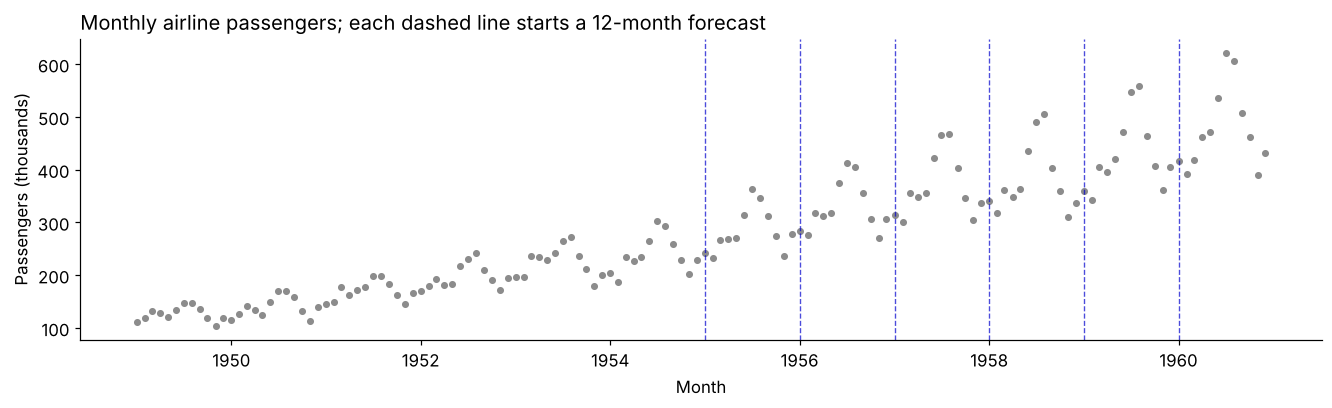

144 months, from 1949-01 to 1960-12. 1960 carried 3.8 times the passengers of 1949.


In [2]:
passengers = load("airline-passengers").astype(float)
history_lengths = (72, 84, 96, 108, 120, 132)  # the history ends in December 1954, 1955, ..., 1959

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
ax.scatter(passengers.index.to_timestamp(), passengers["passengers"], color="0.55", s=13)
for n in history_lengths:
    ax.axvline(passengers.index[n].to_timestamp(), color="#0000CC", linestyle="--", linewidth=0.9, alpha=0.7)
ax.set(title="Monthly airline passengers; each dashed line starts a 12-month forecast",
       xlabel="Month", ylabel="Passengers (thousands)")
plt.show()
print(f"{len(passengers)} months, from {passengers.index[0]} to {passengers.index[-1]}. "
      f"1960 carried {passengers['passengers'].iloc[-12:].sum() / passengers['passengers'].iloc[:12].sum():.1f} "
      "times the passengers of 1949.")

## A backtest that looks fine

We test the way most teams would. Six times, we hide a year: the model gets the history up to a December and must forecast the next 12 months. `cases_from_series` cuts the six cases, and `pipeline.run` fits a fresh copy of the model on each history, so no forecast can see the months it is scored on.

Two models:

- **Same month last year**: repeat the last 12 months. The usual benchmark for monthly data.
- **Forest**: scikit-learn's `RandomForestRegressor` with its default settings, predicting each month from the 12 before it. `Pipeline(..., window_length=12)` builds those inputs and feeds each forecast back in to reach 12 months ahead.

We score each forecast with MASE(12): its average miss, divided by the average miss of "same month last year" inside that history. Lower is better.

In [3]:
cases = cases_from_series(passengers, origins=history_lengths, horizon=12, name="airline passengers")


def backtest(models):
    "Run each model on the six cases. Returns the runs and a table of MASE(12) per date."
    runs = {name: model.run(cases=cases, metrics={"mase_12": partial(mase, seasonality=12)}, keep_data=True)
            for name, model in models.items()}
    table = pd.DataFrame({name: run.metrics.set_index("origin")["mase_12"] for name, run in runs.items()})
    table = table.rename_axis("history ends")
    table.loc["average"] = table.mean()
    return runs, table


benchmark = Pipeline(SeasonalLastValueForecaster(period=12))
forest = Pipeline(RandomForestRegressor(random_state=0), window_length=12, name="Forest")
runs, scores = backtest({"Same month last year": benchmark, "Forest": forest})
display(scores.round(2))
forest_wins = int((scores["Forest"] < scores["Same month last year"]).iloc[:-1].sum())
print(f"The forest beats the benchmark at {forest_wins} of {len(cases)} dates.")
assert forest_wins == 5

,Same month last year,Forest
history ends,,
1954-12,1.96,1.55
1955-12,1.66,0.79
1956-12,1.38,1.09
1957-12,0.41,1.59
1958-12,1.66,1.13
1959-12,1.57,0.84
average,1.44,1.17


The forest beats the benchmark at 5 of 6 dates.


The forest wins at five of the six dates, and its average miss is about a fifth smaller. It loses only in 1958, a year when traffic barely grew and repeating 1957 was hard to beat. By the usual standard, this model is ready.

## What the scorecard says

A backtest on one series tells you how the model did on that history. The scorecard asks a different question: on which kinds of series can this model forecast well at all? TimeGym generates ten kinds of series whose best possible forecast it knows, at two noise levels, and scores the model against that answer key. This takes about half a minute for a forest.

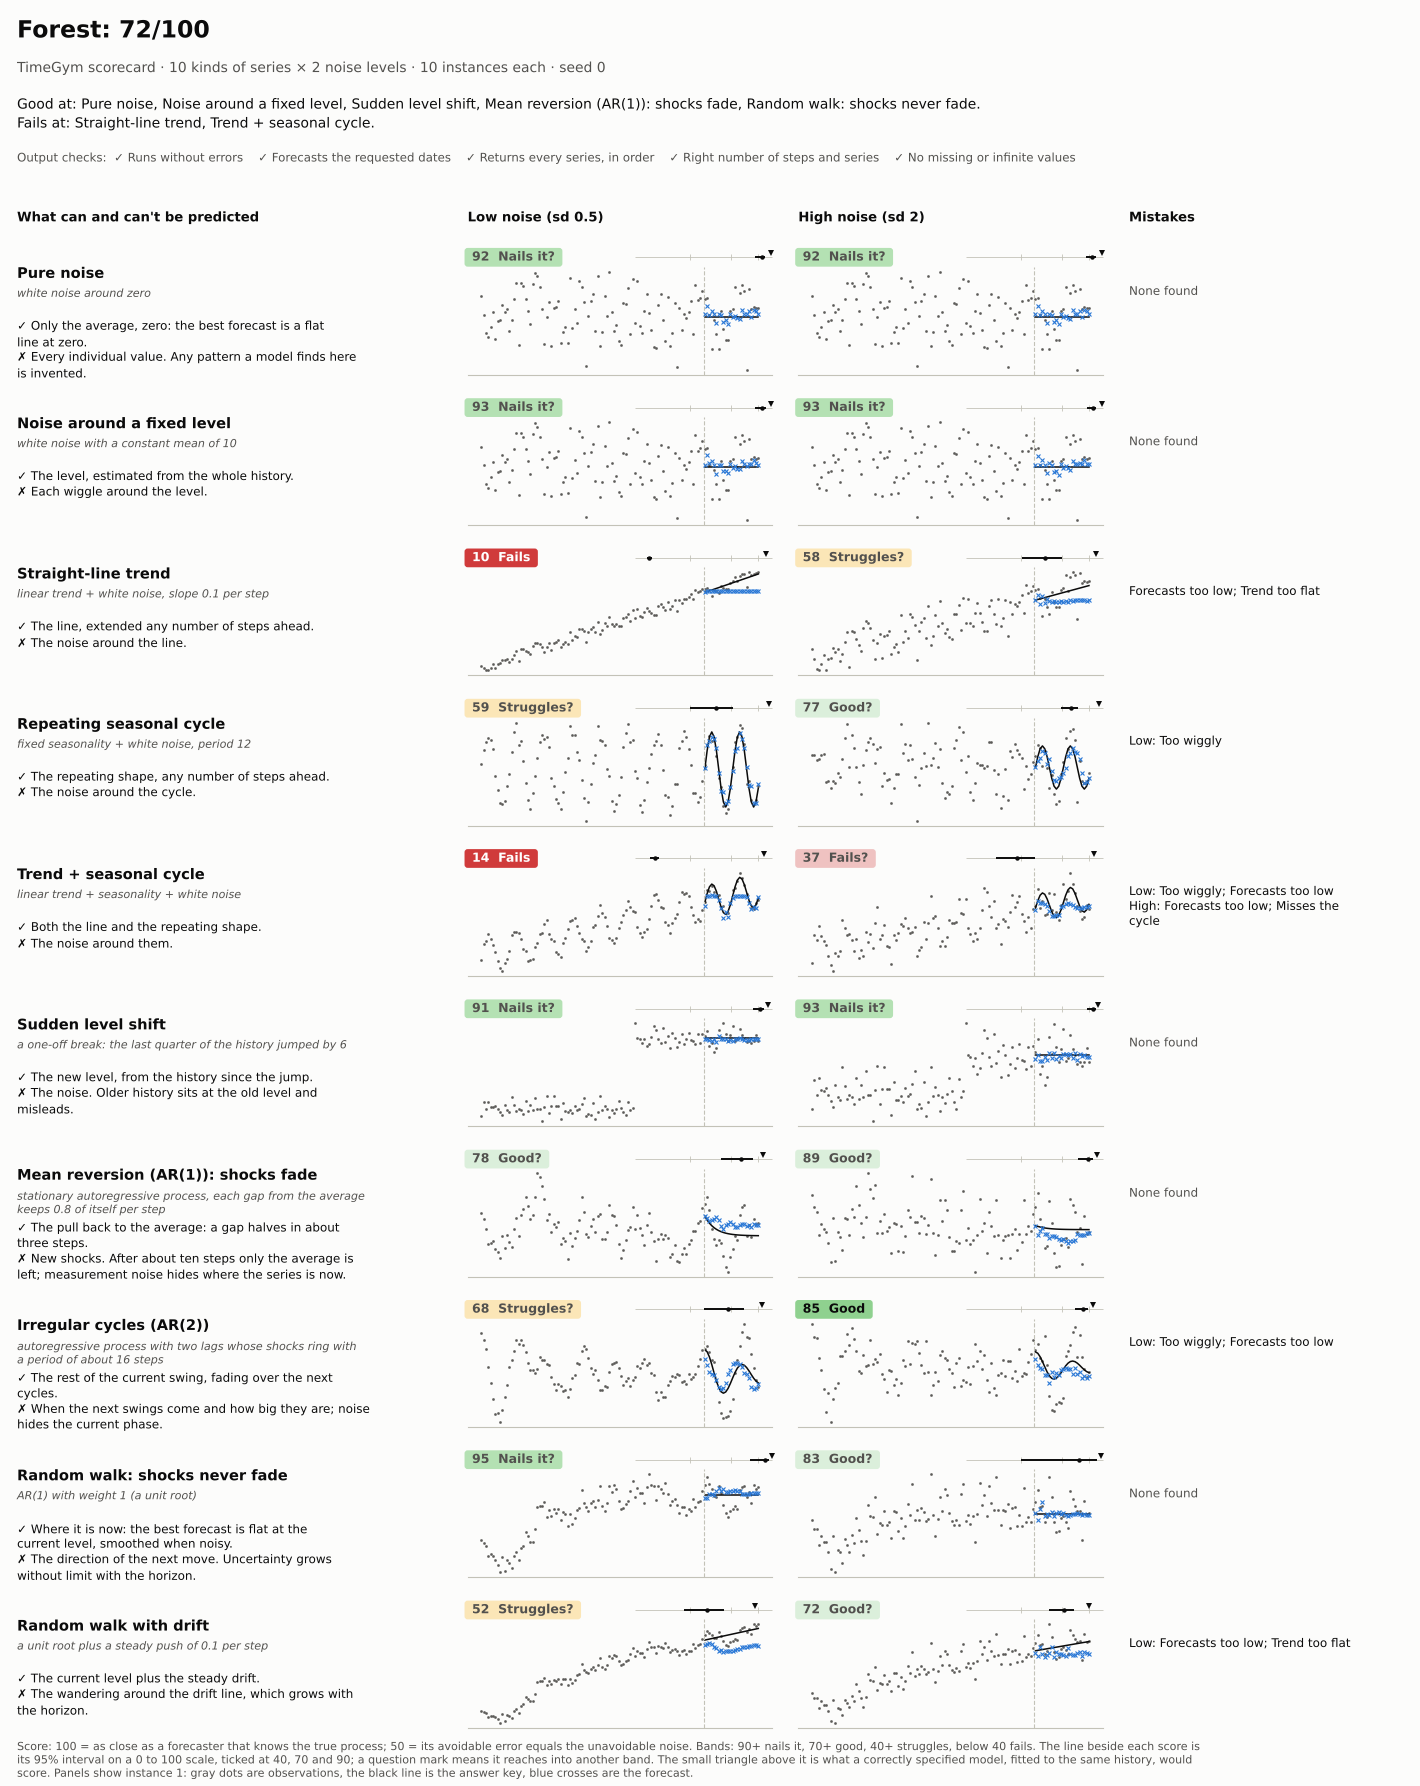

In [4]:
forest_card = forest.run().scorecard
forest_card

The forest scores 72 out of 100, and the card is uneven. It nails noise, fixed levels and sudden level shifts. It **fails the straight-line trend** at low noise, and the mistakes column says how: "Forecasts too low; Trend too flat". It also fails the trend with a seasonal cycle at both noise levels, which is the kind of series an airline has.

The same rows, as a table:

In [5]:
forest_table = forest_card.table.set_index(["pattern", "noise"])
display(forest_card.table.loc[forest_card.table["pattern"].isin(["trend", "trend_seasonal"]),
                              ["title", "noise", "score", "verdict", "mistakes"]]
        .round({"score": 0}).set_index(["title", "noise"]))
assert forest_table.loc[("trend", "Low noise"), "score"] < 40           # fails a plain trend
assert "Forecasts too low" in forest_table.loc[("trend", "Low noise"), "mistakes"]
assert forest_table.loc[("level", "Low noise"), "score"] >= 90          # while it nails a fixed level

score    verdict  \
title                  noise                          
Straight-line trend    Low noise    10.0      Fails   
                       High noise   58.0  Struggles   
Trend + seasonal cycle Low noise    14.0      Fails   
                       High noise   37.0      Fails   

                                                              mistakes  
title                  noise                                            
Straight-line trend    Low noise     Forecasts too low; Trend too flat  
                       High noise    Forecasts too low; Trend too flat  
Trend + seasonal cycle Low noise         Too wiggly; Forecasts too low  
                       High noise  Forecasts too low; Misses the cycle

## The same mistake, on the real data

Once the scorecard has named the mistake, it is easy to find in the backtest. For each of the six dates, the plot shows the forest's forecast as blue crosses and, as a dashed line, the busiest month the model had seen so far.

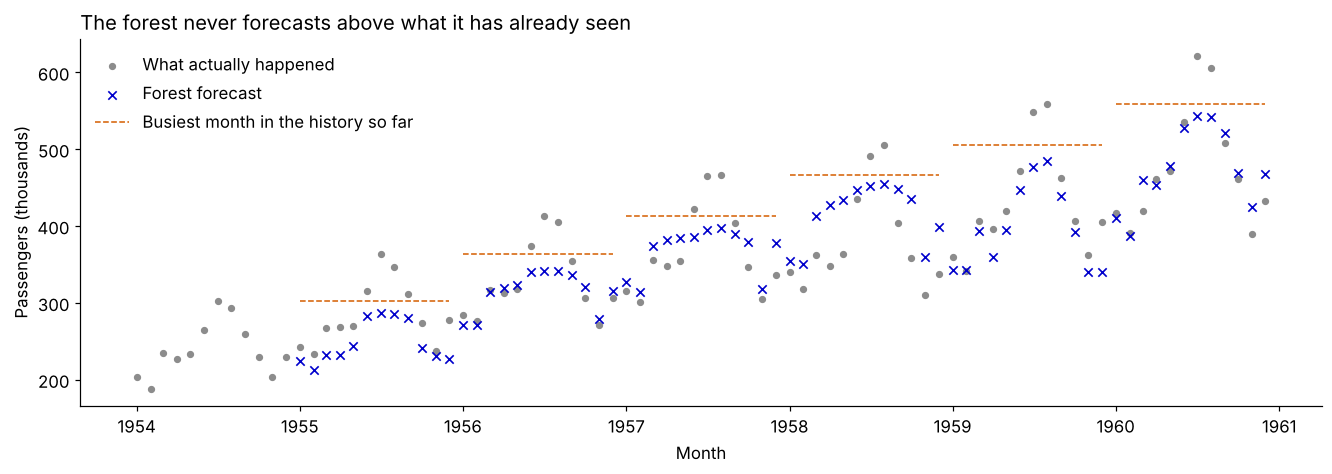

,busiest month so far,highest forecast,busiest month that followed
history ends,,,
1954-12,302,286,364
1955-12,364,342,413
1956-12,413,397,467
1957-12,467,455,505
1958-12,505,485,559
1959-12,559,544,622


In [6]:
fig, ax = plt.subplots(figsize=(12, 4.2), layout="constrained")
months = passengers.index.to_timestamp()
ax.scatter(months[60:], passengers["passengers"].iloc[60:], color="0.55", s=14, label="What actually happened")
rows = []
for i, (case, entry) in enumerate(zip(cases, runs["Forest"].cases)):
    forecast, seen = entry.forecast.point[:, 0], case.task.history["passengers"].max()
    future = case.task.future_index.to_timestamp()
    ax.scatter(future, forecast, marker="x", s=30, color="#0000CC", linewidths=1.1,
               label="Forest forecast" if i == 0 else None)
    ax.hlines(seen, future[0], future[-1], color="#D55E00", linestyle="--", linewidth=1,
              label="Busiest month in the history so far" if i == 0 else None)
    rows.append({"history ends": case.manifest["origin"], "busiest month so far": seen,
                 "highest forecast": forecast.max(),
                 "busiest month that followed": case.observed["passengers"].max()})
ax.set(title="The forest never forecasts above what it has already seen",
       xlabel="Month", ylabel="Passengers (thousands)")
ax.legend(loc="upper left")
plt.show()
ceiling = pd.DataFrame(rows).set_index("history ends")
display(ceiling.round(0).astype(int))
assert (ceiling["highest forecast"] < ceiling["busiest month so far"]).all()
assert (ceiling["busiest month that followed"] > ceiling["busiest month so far"]).all()

At every date the forest's highest forecast sits below the busiest month it had already seen, and every time the following summer went well above it. A forest predicts by averaging values from its training data, so it cannot return a number higher than any it was trained on. On a business that grows, that is a forecast that is too low every single year.

It still beat "same month last year", because that rule ignores growth as well: it is always exactly one year behind. Beating a benchmark with the same blind spot proved little.

## The textbook fix: forecast the changes

The usual advice is to stop asking the forest for the level. Month-to-month changes stay in a familiar range while the level climbs, so we let the forest forecast the changes and add them back up. In TimeGym that is one argument, `target_transform=DifferenceTransform()`, and the pipeline converts the forecasts back to passengers.

In [7]:
forest_on_changes = Pipeline(RandomForestRegressor(random_state=0), window_length=12,
                             target_transform=DifferenceTransform(), name="Forest on changes")
more_runs, more_scores = backtest({"Forest on changes": forest_on_changes})
runs.update(more_runs)
scores["Forest on changes"] = more_scores["Forest on changes"]
display(scores.round(2))
assert scores.loc["average", "Forest on changes"] < scores.loc["average", "Forest"]

,Same month last year,Forest,Forest on changes
history ends,,,
1954-12,1.96,1.55,1.80
1955-12,1.66,0.79,0.45
1956-12,1.38,1.09,0.51
1957-12,0.41,1.59,0.54
1958-12,1.66,1.13,1.33
1959-12,1.57,0.84,0.46
average,1.44,1.17,0.85


The average miss drops by about a quarter, and the forest on changes beats the plain forest at four of the six dates. Most teams would ship it here. We ask the scorecard first.

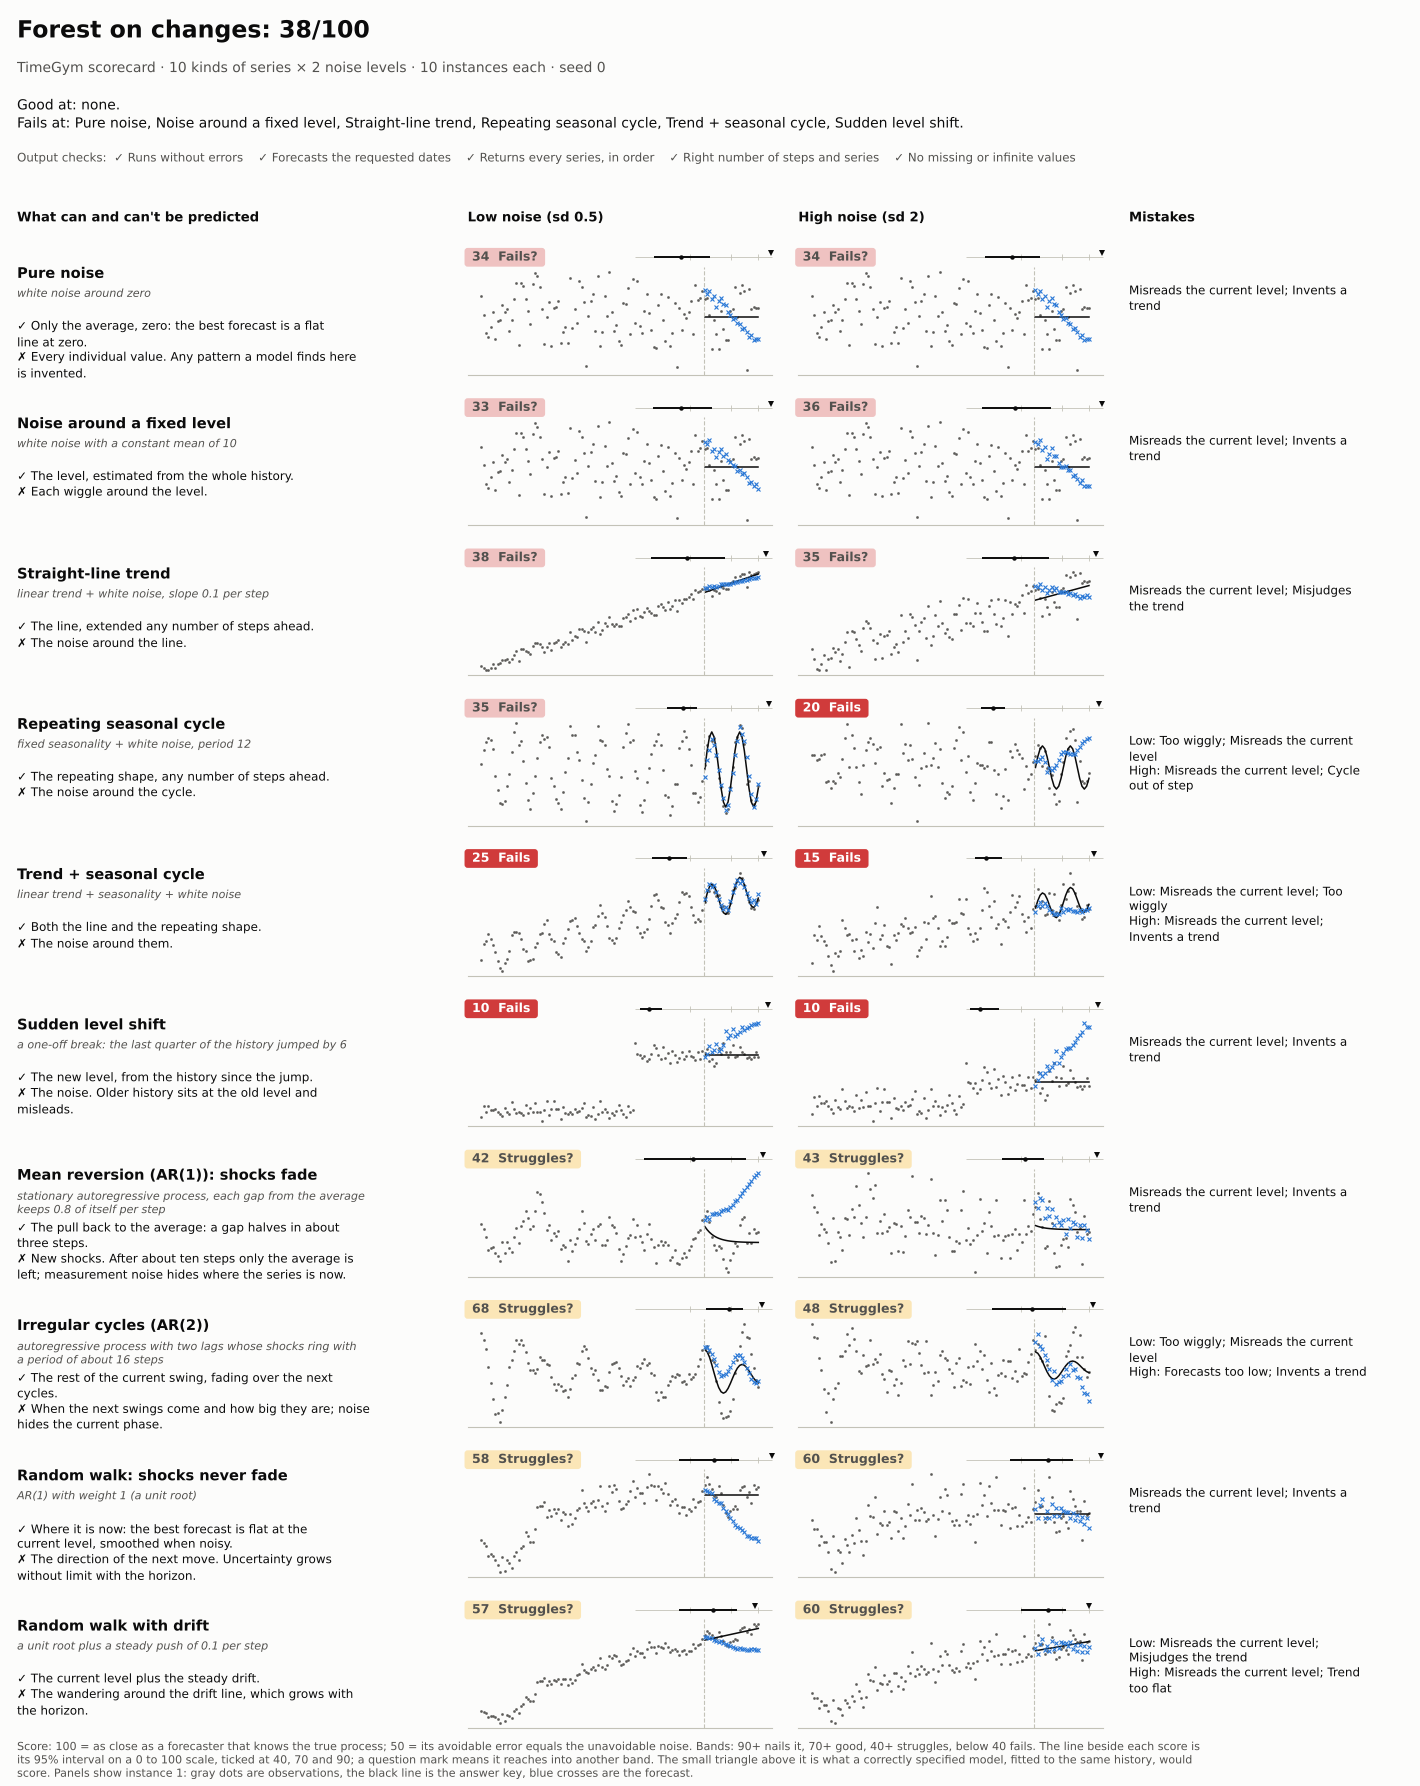

In [8]:
changes_card = forest_on_changes.run().scorecard
changes_card

The score falls from 72 to 38. The trend rows still fail, and now nearly everything else does too. Plain noise around a fixed level, which the forest nailed, drops to the thirties with the mistakes "Misreads the current level; Invents a trend". The sudden level shift goes from above 90 to 10.

The reason is in the adding up. Each forecast change is a little off, and summing 24 of them lets the forecast drift away from the level: in the top panels the blue crosses slide off a series that is only noise. Where the series wobbles around a level there was nothing to fix, and the fix broke it. The backtest had a hint of this that is easy to wave away: at two of the six dates, the forest on changes did worse than the plain one.

## A learner that can extrapolate

The forest's limit is the learner, not the inputs. A linear regression predicts a weighted sum of the last 12 months, so it can continue a line past anything it has seen. We keep the same inputs and swap the learner.

In [9]:
linear = Pipeline(LinearRegression(), window_length=12, name="Linear")
linear_card = linear.run().scorecard

side_by_side = pd.DataFrame({
    "Kind of series": forest_card.table["title"], "Noise": forest_card.table["noise"],
    "Forest": forest_card.table["score"], "Forest on changes": changes_card.table["score"],
    "Linear": linear_card.table["score"],
}).set_index(["Kind of series", "Noise"]).round(0).astype(int)
overall = pd.Series({"Forest": forest_card.score, "Forest on changes": changes_card.score,
                     "Linear": linear_card.score}).round(0).astype(int)
side_by_side.loc[("All kinds of series", "both"), :] = overall
display(side_by_side.astype(int))

linear_table = linear_card.table.set_index(["pattern", "noise"])
assert changes_card.score < forest_card.score < linear_card.score
assert linear_table.loc[("trend", "Low noise"), "score"] >= 70           # the trend is no longer a problem
assert linear_table.loc[("trend_seasonal", "Low noise"), "score"] >= 70

Forest  Forest on changes  \
Kind of series                      Noise                                   
Pure noise                          Low noise       92                 34   
                                    High noise      92                 34   
Noise around a fixed level          Low noise       93                 33   
                                    High noise      93                 36   
Straight-line trend                 Low noise       10                 38   
                                    High noise      58                 35   
Repeating seasonal cycle            Low noise       59                 35   
                                    High noise      77                 20   
Trend + seasonal cycle              Low noise       14                 25   
                                    High noise      37                 15   
Sudden level shift                  Low noise       91                 10   
                                    High noise      93                 10   
Mean reversion (AR(1)): shocks fade Low noise       78                 42   
                                    High noise      89                 43   
Irregular cycles (AR(2))            Low noise       68                 68   
                                    High noise      85                 48   
Random walk: shocks never fade      Low noise       95                 58   
                                    High noise      83                 60   
Random walk with drift              Low noise       52                 57   
                                    High noise      72                 60   
All kinds of series                 both            72                 38   

                                                Linear  
Kind of series                      Noise               
Pure noise                          Low noise       95  
                                    High noise      95  
Noise around a fixed level          Low noise       95  
                                    High noise      95  
Straight-line trend                 Low noise       86  
                                    High noise      87  
Repeating seasonal cycle            Low noise       77  
                                    High noise      76  
Trend + seasonal cycle              Low noise       71  
                                    High noise      68  
Sudden level shift                  Low noise       54  
                                    High noise      91  
Mean reversion (AR(1)): shocks fade Low noise       85  
                                    High noise      95  
Irregular cycles (AR(2))            Low noise       85  
                                    High noise      90  
Random walk: shocks never fade      Low noise       85  
                                    High noise      95  
Random walk with drift              Low noise       61  
                                    High noise      47  
All kinds of series                 both            82

The linear model scores 82. Both trend rows are "Good", and so is the trend with a seasonal cycle at low noise. It is not perfect: it struggles with a sudden level shift at low noise and with a random walk that drifts, which is worth knowing before a strike or a fare war changes the level overnight.

Now the backtest, on the same six dates:

,Same month last year,Forest,Forest on changes,Linear
history ends,,,,
1954-12,1.96,1.55,1.80,1.02
1955-12,1.66,0.79,0.45,0.47
1956-12,1.38,1.09,0.51,0.34
1957-12,0.41,1.59,0.54,1.20
1958-12,1.66,1.13,1.33,0.58
1959-12,1.57,0.84,0.46,0.48
average,1.44,1.17,0.85,0.68


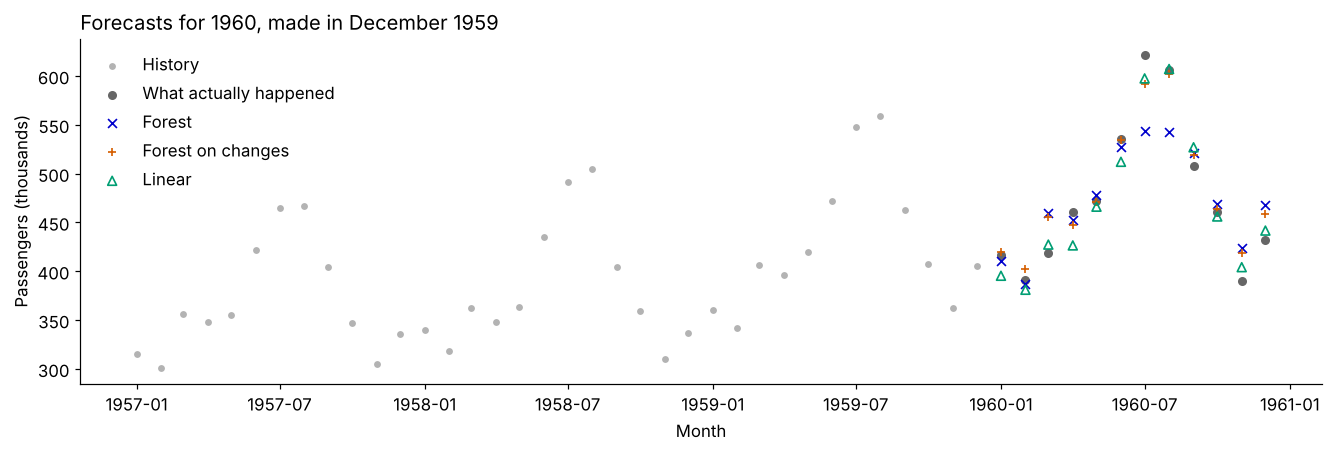

In [10]:
more_runs, more_scores = backtest({"Linear": linear})
runs.update(more_runs)
scores["Linear"] = more_scores["Linear"]
display(scores.round(2))

case, future = cases[-1], cases[-1].task.future_index.to_timestamp()
recent = case.task.history.iloc[-36:]
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.scatter(recent.index.to_timestamp(), recent["passengers"], color="0.7", s=12, label="History")
ax.scatter(future, case.observed["passengers"], color="0.4", s=24, label="What actually happened")
styles = {"Forest": ("x", "#0000CC"), "Forest on changes": ("+", "#D55E00"), "Linear": ("^", "#009E73")}
for name, (marker, color) in styles.items():
    ax.scatter(future, runs[name].cases[-1].forecast.point[:, 0], marker=marker, s=34, color=color,
               linewidths=1.1, facecolors="none" if marker == "^" else color, label=name)
ax.set(title="Forecasts for 1960, made in December 1959", xlabel="Month", ylabel="Passengers (thousands)")
ax.legend(loc="upper left")
plt.show()
assert scores.loc["average", "Linear"] == scores.loc["average"].min()

The linear model has the lowest average miss of the four, about half the benchmark's. It is not the best at every date: for 1958, the year traffic stalled, repeating 1957 beat it easily.

Look at the plot for 1960. The plain forest is stuck under its ceiling, while the forest on changes and the linear model both reach the summer peak. On this date you could not tell those two apart, and on the six dates together the gap between them is modest. What separates them is the scorecard: one is good on most kinds of series, the other only held up here because traffic kept climbing.

## What TimeGym added

- The backtest approved a model that cannot forecast growth. The scorecard named the mistake in four words, and the mistake then showed up in every one of the six backtest forecasts.
- The textbook fix looked good on six dates. The scorecard showed that it trades one failure for many, before the model went anywhere near a planning meeting.
- Each check was one call: `pipeline.run(cases=...)` for the backtest and `pipeline.run().scorecard` for the card.

## Change one thing

- Swap in `HistGradientBoostingRegressor`. It is built from trees too: does its scorecard show the same trend rows failing?
- Let the forest forecast the change from the same month a year earlier, with `DifferenceTransform(lag=12)`, and read its scorecard before its backtest.
- Call `forest.run(horizon=6).scorecard`. Does the forecast on changes drift less when it adds up fewer steps?

**What this doesn't show.** Six dates from one series are six looks at one history, not six independent tests, so the backtest cannot rank these models in general. The scorecard's series are generated: their trends and cycles are simpler than real ones, so a good score says what a model can do, not how well it will do on your data. We also left the forest's settings at their defaults; tuning them does not lift the ceiling.

**Related:** [Quick start](../tutorials/01_quick_start.ipynb) reads a scorecard step by step, [Target transforms](../tutorials/04_target_transforms.ipynb) covers forecasting changes and logs, and [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) checks this same series for leaks. More examples are on the [examples page](../docs/examples.md).